In [37]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from slicing_class import adcFitter2

In [38]:
#import data
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov5th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')

In [39]:
len(step)

51

In [40]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.6,speckle_window=60) 

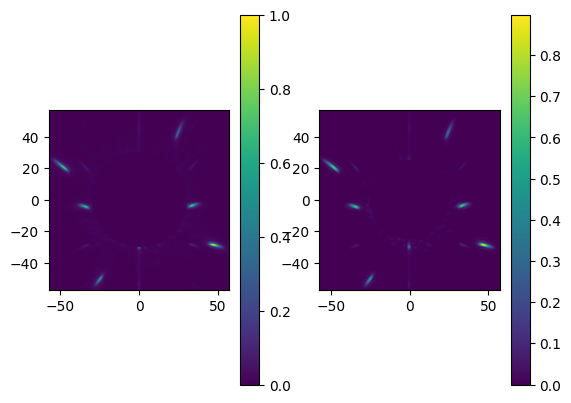

In [41]:
plt.subplot(1,2,1)
imshow_field(ADC.crop_image(step[1]))
plt.colorbar()
plt.subplot(1,2,2)
imshow_field(ADC.filter_image(ADC.crop_image(step[1],mask_diam=50)))
plt.colorbar()

In [42]:
h = ADC.filter_image(ADC.crop_image(step[0],mask_diam=30,extent=500))
q = ADC.slice_speckle_angle(h,0,print_updates=True)

speckle falls off right (top) edge
slope: 0.37
corresponding angle: 0.35 (rad) or 20.29°


speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off left (bottom) edge
speckle falls off right (top) edge
speckle falls off left (bottom) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off right (top) edge
speckle falls off left (bottom) edge
speckle falls off right (top) edge
speckle falls 

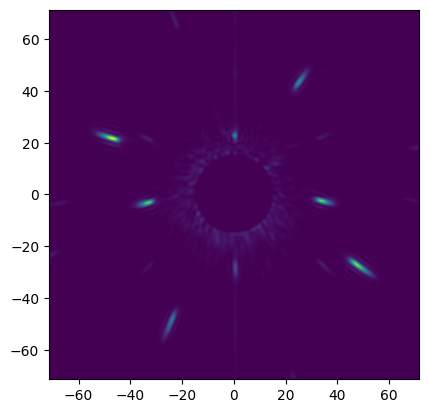

In [43]:
#filter all the image cubes from each step
filtered_sweep = [] #filtered image cube at each step
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = [] 
speckle_list = [] #speckle angle list at each step

for i, field in enumerate(step):
    filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=30,extent=500)) 
    #filtered = ADC.crop_image(ADC.filter_image(field),extent=500,mask_diam=60) 
    imshow_field(filtered)
    a = ADC.all_speckle_angles(filtered)
    speckle_list.append(a)
    diffs13_list.append(a[0] - a[2])
    diffs24_list.append(a[1] - a[3])

diffs13_list = np.array(diffs13_list)
diffs24_list = np.array(diffs24_list)

In [44]:
diffs13_list

array([-10.74032493,          nan,          nan,  -8.88872749,
        -8.92032499,  -8.59967869,  -7.34067621,  -7.06982924,
        -6.97559666,  -7.07405609,          nan,  -5.96173765,
        -9.27431533,  -5.78317434,          nan,  -4.41804101,
        -4.1111677 ,  -3.15586345,  -3.25265869,  -2.40463012,
        -2.41498704,  -1.66750994,  -1.11835863,  -0.87676453,
        -0.62445706,  -0.41490632,   0.27323657,   0.62013461,
         0.832384  ,   1.14070638,   1.65901278,   1.82017811,
         2.47051524,   2.54220363,   2.94252589,   3.50274065,
         3.73856944,   4.16111308,   4.13360894,   5.16638913,
         5.34609335,   5.65404831,   5.86310013,   6.26040775,
         6.9332383 ,   7.06309542,   7.63040909,   8.13150302,
         8.35147026,   9.01997769,          nan])

Slope of Speckles 1&3 Response: 1.9706911724513154
Offset of Speckles 1&3 Response: -1.5233838382914842
Slope of Speckles 2&4 Response: -4.272418046588413
Offset of Speckles 2&4 Response: 4.813752710077593


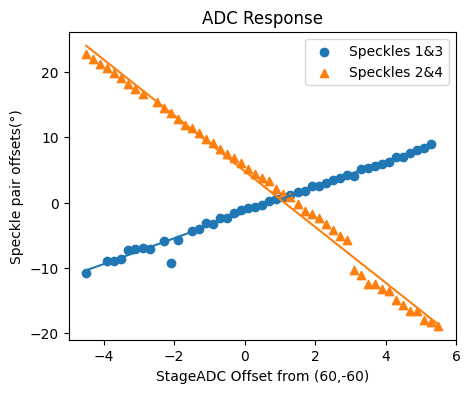

In [45]:
#plot the linear response
# offsets = np.array([-1, -0.5, -0.3, -0.1, 0, 0.1, 0.3, 0.5, 1]) -0.5
# offsets = np.flip(offsets)
angle_offsets = np.linspace(-5,5,51) + 0.5

b1 = np.zeros(2)
m1 = np.zeros(2)

#only consider finite angles (clean up nan values)
idxs13 = np.isfinite(diffs13_list)
idxs24 = np.isfinite(diffs24_list)

h = [diffs13_list, diffs24_list]

avgs = [diffs13_list[idxs13], diffs24_list[idxs24]]
offsets = [angle_offsets[idxs13],angle_offsets[idxs24]]

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    plt.scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    plt.plot(offsets[j], linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')


plt.title('ADC Response')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Speckle pair offsets(°)')
plt.legend()
plt.show()

In [46]:
#finding the response/control matrices
response = np.matrix([m1])
ctrl_matrix = np.linalg.pinv(response)
print(ctrl_matrix.T)

ctrl_matrix = ctrl_matrix.T
print(ctrl_matrix)

ADC.control_matrix = ctrl_matrix

[[ 0.08902178 -0.1929974 ]]
[[ 0.08902178 -0.1929974 ]]


In [47]:
commands = []

for i in range(len(diffs13_list)):
    measurement = np.array([h[0][i],h[1][i]])
    if np.isfinite(measurement.all()):
        commands.append(-np.squeeze(ADC.calculate_command(measurement.T)))

commands = np.array(commands)
command_idxs = np.isfinite(commands)

slope: 1.0060002733356523
offset: -1.080558122732287


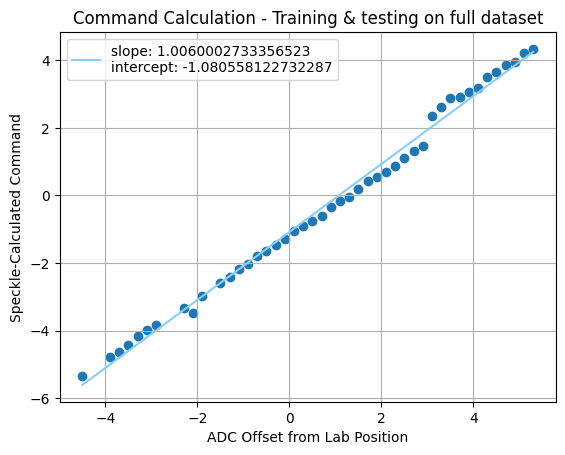

In [48]:
#plotting versus the actual angles:
m, b = np.polyfit(angle_offsets[command_idxs],commands[command_idxs],deg=1)

print(f'slope: {m}')
print(f'offset: {b}')

plt.scatter(angle_offsets[command_idxs],commands[command_idxs])
plt.plot(angle_offsets[command_idxs], m * angle_offsets[command_idxs] + b,color='lightskyblue',label=f'slope: {m}\nintercept: {b}')
plt.title('Command Calculation - Training & testing on full dataset')
plt.xlabel('ADC Offset from Lab Position')
plt.ylabel('Speckle-Calculated Command')
plt.legend()
plt.grid()
plt.show()